In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações visuais dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

# Para exibir todas as colunas no pandas
pd.set_option('display.max_columns', None)

In [4]:
# Modifique o caminho do arquivo conforme a estrutura do seu projeto
DATA_PATH = "../data/data_raw/customer_churn_telecom_services.csv" 

df = pd.read_csv(DATA_PATH)


print(f"Dimensões do Dataset: {df.shape[0]} linhas e {df.shape[1]} colunas.")
df.head()

Dimensões do Dataset: 7043 linhas e 20 colunas.


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [6]:
missing_summary = pd.DataFrame({
    'Valores Nulos (Qtd)': df.isnull().sum(),
    'Porcentagem (%)': (df.isnull().sum() / len(df)) * 100
})

missing_summary = missing_summary[missing_summary['Valores Nulos (Qtd)'] > 0]

if not missing_summary.empty:
    print("--- Colunas com Valores Ausentes ---")
    display(missing_summary)
else:
    print("Nenhum valor nulo encontrado diretamente após a limpeza inicial.")

--- Colunas com Valores Ausentes ---


,Valores Nulos (Qtd),Porcentagem (%)
TotalCharges,11,0.156183


In [7]:
# Análise de variáveis numéricas continuas/discretas
num_cols = df.select_dtypes(include=[np.number]).columns

print("--- Estatísticas Descritivas (Variáveis Numéricas) ---")
df[num_cols].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]

--- Estatísticas Descritivas (Variáveis Numéricas) ---


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.00,0.000,0.0000,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80


In [9]:
cat_cols = df.select_dtypes(include=['object']).columns

cat_summary = pd.DataFrame({
    'Valores Únicos': df[cat_cols].nunique(),
    'Exemplo de Valores': [df[col].unique()[:3].tolist() for col in cat_cols]
})

print("--- Resumo de Variáveis Categóricas ---")
display(cat_summary)

--- Resumo de Variáveis Categóricas ---


,Valores Únicos,Exemplo de Valores
gender,2,"[Female, Male]"
Partner,2,"[Yes, No]"
Dependents,2,"[No, Yes]"
PhoneService,2,"[No, Yes]"
MultipleLines,3,"[No phone service, No, Yes]"
InternetService,3,"[DSL, Fiber optic, No]"
OnlineSecurity,3,"[No, Yes, No internet service]"
OnlineBackup,3,"[Yes, No, No internet service]"
DeviceProtection,3,"[No, Yes, No internet service]"
TechSupport,3,"[No, Yes, No internet service]"


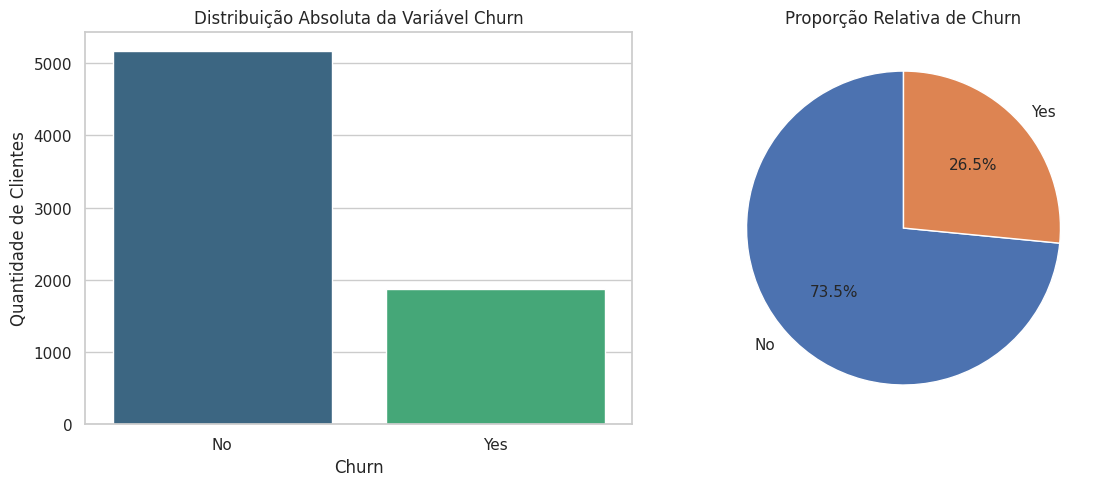

In [15]:
target_col = "Churn"

if target_col in df.columns:
    churn_counts = df[target_col].value_counts()
    churn_perc = df[target_col].value_counts(normalize=True) * 100

    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    # Gráfico de Barras
    sns.countplot(data=df, x=target_col, hue=target_col, ax=ax[0], palette="viridis", legend=False)
    ax[0].set_title("Distribuição Absoluta da Variável Churn")
    ax[0].set_ylabel("Quantidade de Clientes")

    # Gráfico de Pizza
    ax[1].pie(churn_counts, labels=churn_counts.index, autopct='%1.1f%%', colors=['#4C72B0', '#DD8452'], startangle=90)
    ax[1].set_title("Proporção Relativa de Churn")

    plt.tight_layout()
    plt.show()
